## Data Preprocessing & Feature Extraction
#### Project: Predictive Maintenance in Aircraft using Machine Learning
#### Dataset: NASA C-MAPS — FD001 (train / test / RUL)


## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE
from sklearn.linear_model import Lasso

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Load the Dataset

The NASA C-MAPS FD001 dataset has **no header row**. We assign column names manually:
- `id` — engine unit number
- `cycle` — time cycle (like a timestamp)
- `setting1`, `setting2`, `setting3` — operational settings
- `sensor1` … `sensor21` — 21 sensor measurements

In [2]:

from pathlib import Path
import pandas as pd

# Get the main project directory
PROJECT_DIR = Path.cwd().parent

# Dataset folder
DATA_DIR = PROJECT_DIR / "data" / "raw" / "CMAPSSData"

# Dataset file paths
train_path = DATA_DIR / "train_FD001.txt"
test_path = DATA_DIR / "test_FD001.txt"
rul_path = DATA_DIR / "RUL_FD001.txt"

# Check that all dataset files exist
for file_path in [train_path, test_path, rul_path]:
    if not file_path.exists():
        raise FileNotFoundError(f"Dataset file not found: {file_path}")

# Column names
col_names = (
    ['id', 'cycle', 'setting1', 'setting2', 'setting3']
    + [f'sensor{i}' for i in range(1, 22)]
)

# Load datasets
df_train = pd.read_csv(
    train_path, sep=r'\s+', header=None, names=col_names
)

df_test = pd.read_csv(
    test_path, sep=r'\s+', header=None, names=col_names
)

df_rul = pd.read_csv(
    rul_path, sep=r'\s+', header=None, names=['RUL']
)

# Display information
print("Train shape:", df_train.shape)
print("Test shape:", df_test.shape)
print("RUL shape:", df_rul.shape)

print("\nTrain Data Info")
df_train.info()

print("\nFirst 5 Rows")
display(df_train.head())


Train shape: (20631, 26)
Test shape: (13096, 26)
RUL shape: (100, 1)

Train Data Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        20631 non-null  int64  
 1   cycle     20631 non-null  int64  
 2   setting1  20631 non-null  float64
 3   setting2  20631 non-null  float64
 4   setting3  20631 non-null  float64
 5   sensor1   20631 non-null  float64
 6   sensor2   20631 non-null  float64
 7   sensor3   20631 non-null  float64
 8   sensor4   20631 non-null  float64
 9   sensor5   20631 non-null  float64
 10  sensor6   20631 non-null  float64
 11  sensor7   20631 non-null  float64
 12  sensor8   20631 non-null  float64
 13  sensor9   20631 non-null  float64
 14  sensor10  20631 non-null  float64
 15  sensor11  20631 non-null  float64
 16  sensor12  20631 non-null  float64
 17  sensor13  20631 non-null  float64
 18  sensor14  20631 non-

,id,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor12,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


---
##  Data Preprocessing

- `setting3` is a constant/NaN artifact column with no predictive value → **dropped**
- `sensor20` and `sensor21` are entirely `NaN` in FD001 → **dropped**

In [3]:
print("Shape BEFORE cleaning:", df_train.shape)

# Drop setting 3
df_train.drop(columns=['setting3'], inplace=True, errors='ignore')
df_test.drop( columns=['setting3'], inplace=True, errors='ignore')
print("Dropped 'setting3' (constant artifact column).")

# Drop columns fully Nan (sensor20, sensor21 in FD001)
null_counts = df_train.isnull().sum()
fully_null  = null_counts[null_counts == len(df_train)].index.tolist()
print(f"Columns fully NaN will be dropped: {fully_null}")

df_train.drop(columns=fully_null, inplace=True, errors='ignore')
df_test.drop( columns=fully_null, inplace=True, errors='ignore')

# Verify remaining missing values
remaining_nulls_train = df_train.isnull().sum().sum()
remaining_nulls_test  = df_test.isnull().sum().sum()
print()
print(f"Remaining missing values Train: {remaining_nulls_train}, Test: {remaining_nulls_test}")

print()
print("Shape after removing null columns:", df_train.shape)

print(df_train.isnull().sum())

Shape BEFORE cleaning: (20631, 26)
Dropped 'setting3' (constant artifact column).
Columns fully NaN will be dropped: []

Remaining missing values Train: 0, Test: 0

Shape after removing null columns: (20631, 25)
id          0
cycle       0
setting1    0
setting2    0
sensor1     0
sensor2     0
sensor3     0
sensor4     0
sensor5     0
sensor6     0
sensor7     0
sensor8     0
sensor9     0
sensor10    0
sensor11    0
sensor12    0
sensor13    0
sensor14    0
sensor15    0
sensor16    0
sensor17    0
sensor18    0
sensor19    0
sensor20    0
sensor21    0
dtype: int64


### Remove Duplicate Records

In [4]:
print("TRAIN ")
print(f"Duplicate rows BEFORE: {df_train.duplicated().sum()}")
df_train.drop_duplicates(inplace=True)
print(f"Duplicate rows AFTER : {df_train.duplicated().sum()}")

print("\n TEST")
print(f"Duplicate rows BEFORE: {df_test.duplicated().sum()}")
df_test.drop_duplicates(inplace=True)
print(f"Duplicate rows AFTER : {df_test.duplicated().sum()}")

print("\nTrain shape after dedup:", df_train.shape)
print("Test shape  after dedup:", df_test.shape)

TRAIN 
Duplicate rows BEFORE: 0
Duplicate rows AFTER : 0

 TEST
Duplicate rows BEFORE: 0
Duplicate rows AFTER : 0

Train shape after dedup: (20631, 25)
Test shape  after dedup: (13096, 25)


### Create RUL (Remaining Useful Life) Target Variable

For training data, RUL is not given directly. We calculate it as:

 **RUL = max_cycle_for_engine − current_cycle**



In [8]:
# Maximum cycle per engine = failure point
max_cycle_per_engine = df_train.groupby('id')['cycle'].max()

# Map max cycle back to each row
df_train['max_cycle'] = df_train['id'].map(max_cycle_per_engine)

# RUL = how many cycles remain until failure
df_train['RUL'] = df_train['max_cycle'] - df_train['cycle']

# Drop helper column
df_train.drop(columns=['max_cycle'], inplace=True)

print("RUL column created successfully.")
print("\nSample rows (id, cycle, RUL):")
print(df_train[['id', 'cycle', 'RUL']].head(10))
print()
print("RUL statistics:")
print(df_train['RUL'].describe().round(2))

RUL column created successfully.

Sample rows (id, cycle, RUL):
   id  cycle  RUL
0   1      1  191
1   1      2  190
2   1      3  189
3   1      4  188
4   1      5  187
5   1      6  186
6   1      7  185
7   1      8  184
8   1      9  183
9   1     10  182

RUL statistics:
count    20631.00
mean       107.81
std         68.88
min          0.00
25%         51.00
50%        103.00
75%        155.00
max        361.00
Name: RUL, dtype: float64


###  Detect and Handle Outliers


In [9]:
# Select feature columns only (no id, cycle, RUL)
feature_cols = [c for c in df_train.columns if c not in ['id', 'cycle', 'RUL']]
X_for_outlier = df_train[feature_cols].select_dtypes(include=np.number)

# Temporary scaling for outlier detection
scaler_temp = StandardScaler()
X_temp_scaled = scaler_temp.fit_transform(X_for_outlier)

# Isolation Forest: -1 = outlier, 1 = normal
iso = IsolationForest(contamination=0.05, random_state=42)
outlier_labels = iso.fit_predict(X_temp_scaled)

n_outliers = (outlier_labels == -1).sum()
print(f"Total rows          : {len(df_train)}")
print(f"Outliers detected   : {n_outliers} ({n_outliers/len(df_train)*100:.1f}%)")

# Keep only normal rows
df_train_clean = df_train[outlier_labels == 1].copy()
print(f"Rows after removing : {len(df_train_clean)}")

Total rows          : 20631
Outliers detected   : 1032 (5.0%)
Rows after removing : 19599


### Data Scaling — StandardScaler (Standardization)

Feature columns scaled: (19599, 23)

Before scaling — sensor2 stats:
count    19599.0000
mean       642.6403
std          0.4630
min        641.2100
25%        642.3100
50%        642.6200
75%        642.9500
max        644.3900
Name: sensor2, dtype: float64

After scaling  — sensor2 stats:
count    19599.0000
mean         0.0000
std          1.0000
min         -3.0890
25%         -0.7134
50%         -0.0439
75%          0.6688
max          3.7787
Name: sensor2, dtype: float64


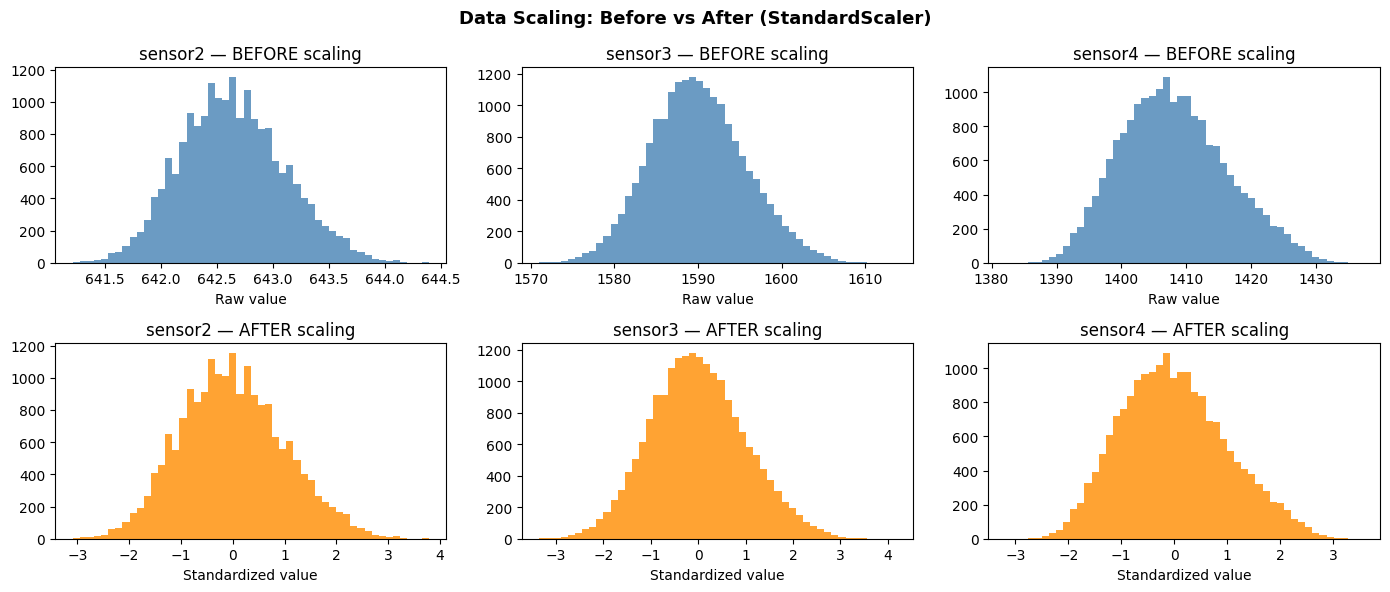

In [10]:
# Feature columns (no id, cycle, RUL)
feature_cols = [c for c in df_train_clean.columns if c not in ['id', 'cycle', 'RUL']]
X_clean = df_train_clean[feature_cols].select_dtypes(include=np.number)

# Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_clean.columns, index=X_clean.index)

print("Feature columns scaled:", X_scaled_df.shape)
print()
print("Before scaling — sensor2 stats:")
print(X_clean['sensor2'].describe().round(4))
print()
print("After scaling  — sensor2 stats:")
print(X_scaled_df['sensor2'].describe().round(4))

# Before vs After Plot
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
sensors_to_show = ['sensor2', 'sensor3', 'sensor4']

for i, s in enumerate(sensors_to_show):
    axes[0, i].hist(X_clean[s], bins=50, color='steelblue', alpha=0.8)
    axes[0, i].set_title(f'{s} — BEFORE scaling')
    axes[0, i].set_xlabel('Raw value')

    axes[1, i].hist(X_scaled_df[s], bins=50, color='darkorange', alpha=0.8)
    axes[1, i].set_title(f'{s} — AFTER scaling')
    axes[1, i].set_xlabel('Standardized value')

plt.suptitle('Data Scaling: Before vs After (StandardScaler)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Feature Extraction

The following techniques are applied:
1. **Statistical Feature Extraction** — mean, std, min, max per engine
2. **Principal Component Analysis (PCA)** — dimensionality reduction
3. **RFE + Lasso** — feature selection (selects top 10 most important features)

### Statistical Feature Extraction

In [11]:
# Aggregate per engine: mean, std, min, max
df_stats = df_train_clean.groupby('id')[X_clean.columns].agg(['mean', 'std', 'min', 'max'])

# Flatten multi-level column names → e.g. 'sensor2_mean'
df_stats.columns = ['_'.join(col) for col in df_stats.columns]
df_stats = df_stats.reset_index()

print("Statistical feature extraction complete.")
print("Shape (one row per engine):", df_stats.shape)
print("\nSample columns (first 8):")
print(df_stats.columns[:8].tolist())
print()
print(df_stats.head(3))

Statistical feature extraction complete.
Shape (one row per engine): (100, 93)

Sample columns (first 8):
['id', 'setting1_mean', 'setting1_std', 'setting1_min', 'setting1_max', 'setting2_mean', 'setting2_std', 'setting2_min']

   id  setting1_mean  setting1_std  setting1_min  setting1_max  setting2_mean  \
0   1      -0.000124      0.001898       -0.0043        0.0047       0.000046   
1   2       0.000071      0.002318       -0.0068        0.0076       0.000083   
2   3       0.000147      0.002122       -0.0064        0.0058      -0.000009   

   setting2_std  setting2_min  setting2_max  sensor1_mean  ...  sensor19_min  \
0      0.000285       -0.0004        0.0005        518.67  ...         100.0   
1      0.000295       -0.0004        0.0006        518.67  ...         100.0   
2      0.000289       -0.0005        0.0005        518.67  ...         100.0   

   sensor19_max  sensor20_mean  sensor20_std  sensor20_min  sensor20_max  \
0         100.0      38.858415      0.148258      

### Cell 10: Principal Component Analysis (PCA)

Components needed to explain 95% variance: 13


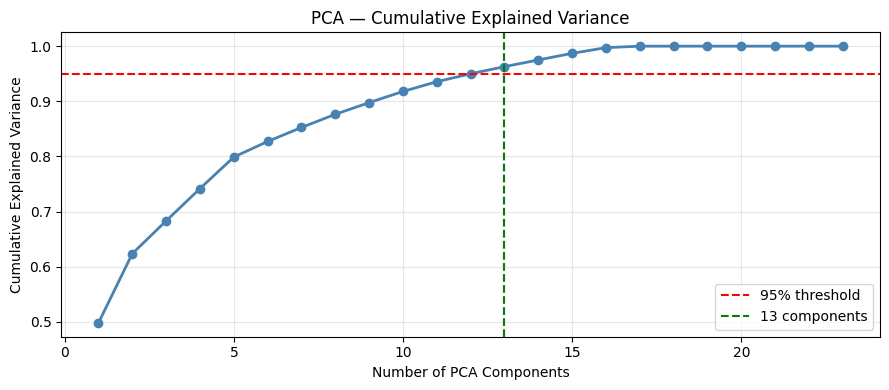


Original feature shape : (19599, 23)
After PCA shape        : (19599, 13)

Variance explained by each component:
[0.4982 0.1256 0.0594 0.0585 0.0572 0.0282 0.0254 0.0239 0.0212 0.0202
 0.0177 0.0144 0.0129]


In [12]:
# Fit PCA on scaled data (all components first to see variance)
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_95   = np.argmax(cumvar >= 0.95) + 1
print(f"Components needed to explain 95% variance: {n_95}")

# Plot cumulative variance
plt.figure(figsize=(9, 4))
plt.plot(range(1, len(cumvar)+1), cumvar, marker='o', color='steelblue', linewidth=2)
plt.axhline(y=0.95, color='red', linestyle='--', label='95% threshold')
plt.axvline(x=n_95, color='green', linestyle='--', label=f'{n_95} components')
plt.xlabel('Number of PCA Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA — Cumulative Explained Variance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Apply PCA with chosen number of components
pca = PCA(n_components=n_95, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"\nOriginal feature shape : {X_scaled.shape}")
print(f"After PCA shape        : {X_pca.shape}")
print(f"\nVariance explained by each component:")
print(np.round(pca.explained_variance_ratio_, 4))

###  Feature Selection — RFE with Lasso


=== RFE + Lasso Feature Selection ===

Selected features (10):
  ✔ sensor4
  ✔ sensor7
  ✔ sensor8
  ✔ sensor9
  ✔ sensor11
  ✔ sensor12
  ✔ sensor13
  ✔ sensor14
  ✔ sensor15
  ✔ sensor21

Dropped features (13):
  ✘ setting1
  ✘ setting2
  ✘ sensor1
  ✘ sensor2
  ✘ sensor3
  ✘ sensor5
  ✘ sensor6
  ✘ sensor10
  ✘ sensor16
  ✘ sensor17
  ✘ sensor18
  ✘ sensor19
  ✘ sensor20


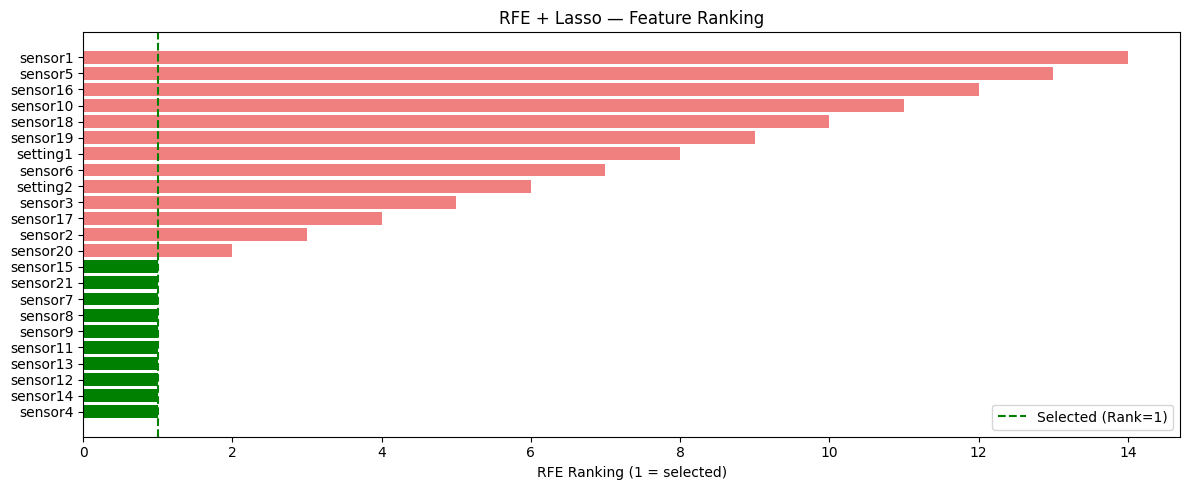

In [13]:
y = df_train_clean['RUL'].values  # Target: RUL

# Lasso as base estimator (alpha controls regularization strength)
lasso = Lasso(alpha=0.1, random_state=42, max_iter=5000)

# RFE: recursively eliminate features until 10 remain
selector = RFE(estimator=lasso, n_features_to_select=10, step=1)
selector.fit(X_scaled, y)

selected_features = X_clean.columns[selector.support_].tolist()
dropped_features  = X_clean.columns[~selector.support_].tolist()

print("=== RFE + Lasso Feature Selection ===")
print(f"\nSelected features ({len(selected_features)}):")
for f in selected_features:
    print(f"  ✔ {f}")

print(f"\nDropped features ({len(dropped_features)}):")
for f in dropped_features:
    print(f"  ✘ {f}")

# Feature ranking bar chart
ranking = selector.ranking_
feature_names = X_clean.columns.tolist()
rank_df = pd.DataFrame({'Feature': feature_names, 'Rank': ranking})
rank_df = rank_df.sort_values('Rank')

plt.figure(figsize=(12, 5))
colors = ['green' if r == 1 else 'lightcoral' for r in rank_df['Rank']]
plt.barh(rank_df['Feature'], rank_df['Rank'], color=colors)
plt.axvline(x=1, color='green', linestyle='--', label='Selected (Rank=1)')
plt.xlabel('RFE Ranking (1 = selected)')
plt.title('RFE + Lasso — Feature Ranking')
plt.legend()
plt.tight_layout()
plt.show()

### Build & Save Final Clean Dataset


=== Final Dataset Summary ===
Shape : (19599, 13)
Columns: ['id', 'cycle', 'RUL', 'sensor4', 'sensor7', 'sensor8', 'sensor9', 'sensor11', 'sensor12', 'sensor13', 'sensor14', 'sensor15', 'sensor21']

   id  cycle  RUL  sensor4  sensor7  sensor8  sensor9  sensor11  sensor12  \
0   1      1  191  1400.60   554.36  2388.06  9046.19     47.47    521.66   
1   1      2  190  1403.14   553.75  2388.04  9044.07     47.49    522.28   
2   1      3  189  1404.20   554.26  2388.08  9052.94     47.27    522.42   
3   1      4  188  1401.87   554.45  2388.11  9049.48     47.13    522.86   
4   1      5  187  1406.22   554.00  2388.06  9055.15     47.28    522.19   

   sensor13  sensor14  sensor15  sensor21  
0   2388.02   8138.62    8.4195   23.4190  
1   2388.07   8131.49    8.4318   23.4236  
2   2388.03   8133.23    8.4178   23.3442  
3   2388.08   8133.83    8.3682   23.3739  
4   2388.04   8133.80    8.4294   23.4044  

Missing values in final dataset: 0


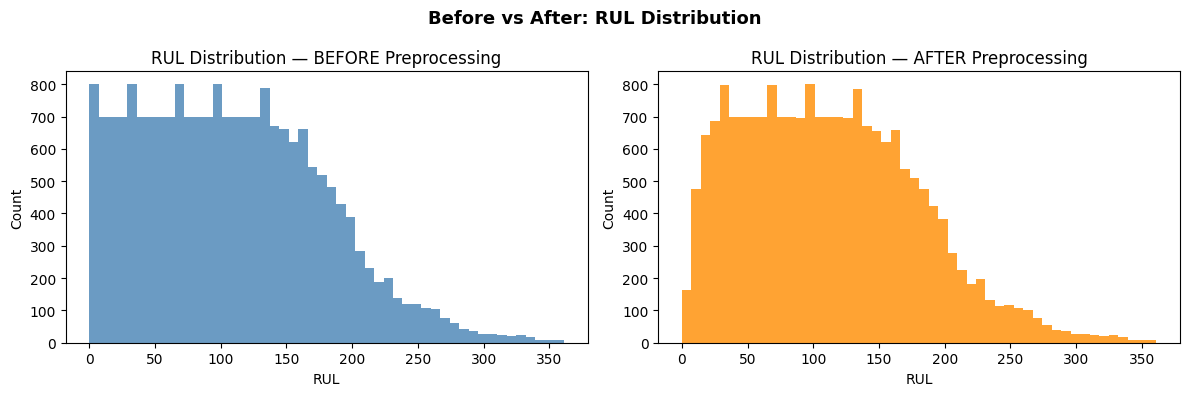


Final dataset saved as: df_final_clean_FD001.csv


In [15]:
# Build final dataset: id + cycle + RUL + selected features only
df_final = df_train_clean[['id', 'cycle', 'RUL']].copy()
df_final = df_final.join(df_train_clean[selected_features])

print("=== Final Dataset Summary ===")
print(f"Shape : {df_final.shape}")
print(f"Columns: {df_final.columns.tolist()}")
print()
print(df_final.head())
print()
print("Missing values in final dataset:", df_final.isnull().sum().sum())

# Before vs After RUL distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(df_train['RUL'],       bins=50, color='steelblue',  alpha=0.8)
ax1.set_title('RUL Distribution — BEFORE Preprocessing')
ax1.set_xlabel('RUL')
ax1.set_ylabel('Count')

ax2.hist(df_train_clean['RUL'], bins=50, color='darkorange', alpha=0.8)
ax2.set_title('RUL Distribution — AFTER Preprocessing')
ax2.set_xlabel('RUL')
ax2.set_ylabel('Count')

plt.suptitle('Before vs After: RUL Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Save to CSV
df_final.to_csv("df_final_clean_FD001.csv", index=False)
print("\nFinal dataset saved as: df_final_clean_FD001.csv")